# Phân tích 3 lần chạy DQN (Flappy Bird)

Ba lần chạy dùng **cùng một cấu hình** (Double + Dueling DQN, `lr=1e-4`, buffer 100k, batch 64, `ε: 1→0.01` trong 100k frame, `random_flap_prob=0.1`, `train_seed=0`, `eval_seed=12345`). Chỉ khác `total_frames`:

| Run | Tổng frame | Thư mục |
|---|---|---|
| dqn1 | 1 triệu | `dqn_run1` |
| dqn2 | 10 triệu | `dqn_run2` |
| dqn3 | 5 triệu | `dqn_run3` |

`total_frames` không tác động vào thuật toán (lịch ε kết thúc ở 100k frame), nên đây là **ba lần lặp của cùng một thí nghiệm, dừng ở ba mốc khác nhau**, không phải ba "cấu hình thời lượng".

Cứ 25 000 frame, agent được đánh giá 20 ván (ε=0, giới hạn 200 ống) và ghi vào `history.jsonl`. Cuối mỗi run, `best.weights.h5` được đánh giá lại 100 ván với giới hạn 1000 ống.

Ba điểm cần biết khi đọc dữ liệu:
- `session_minutes` về 0 mỗi lần notebook Colab được chạy tiếp (resume). Thời gian của một run là tổng đỉnh của từng phiên, và đó vẫn là mức tối thiểu vì phần chạy sau lần đánh giá cuối của mỗi phiên không được ghi.
- `best.weights.h5` là checkpoint **đầu tiên** đạt eval mean cao nhất (so sánh `>`). Vì điểm bị chặn ở 200, với dqn2 và dqn3 đó là lần đầu chạm trần: khung hình 850k (dqn2) và 3,25M (dqn3), không phải cuối run.
- dqn3 có 199 bản ghi thay vì 200: lần đánh giá ở 4.025.000 bị mất vì phiên Colab bị ngắt đúng lúc đang đánh giá.

Số liệu trong các ô nhận xét lấy từ `history.jsonl` và output cuối của 3 notebook Colab. Chạy notebook này từ thư mục gốc của repo; các hình được lưu vào `Results/figures/`.

In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUNS = {"dqn1 (1M)": "Results/dqn_run1", "dqn2 (10M)": "Results/dqn_run2", "dqn3 (5M)": "Results/dqn_run3"}
COLORS = {"dqn1 (1M)": "tab:green", "dqn2 (10M)": "tab:blue", "dqn3 (5M)": "tab:orange"}
FIG_DIR = "Results/figures"
EVAL_EVERY = 25_000
os.makedirs(FIG_DIR, exist_ok=True)

def load(folder):
    rows = [json.loads(line) for line in open(f"{folder}/history.jsonl", encoding="utf8")]
    df = pd.DataFrame(rows)
    for key in ("mean", "median", "min", "max"):
        df[f"eval_{key}"] = df["eval"].map(lambda e: e[key])
    return df.drop(columns="eval")

def session_peaks(df):
    # session_minutes về 0 mỗi lần resume: đỉnh của từng phiên là thời gian phiên đó
    minutes = df.session_minutes.to_numpy()
    restarts = np.flatnonzero(np.diff(minutes) < 0)
    return list(minutes[restarts]) + [minutes[-1]]

def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=100, bbox_inches="tight")

hist = {name: load(folder) for name, folder in RUNS.items()}
for name, df in hist.items():
    missing = sorted(set(range(EVAL_EVERY, df.frame.iloc[-1] + 1, EVAL_EVERY)) - set(df.frame))
    print(f"{name}: {len(df)} điểm đánh giá, frame cuối {df.frame.iloc[-1]:,}, "
          f"{len(session_peaks(df))} phiên Colab, thiếu {missing}")

dqn1 (1M): 40 điểm đánh giá, frame cuối 1,000,000, 2 phiên Colab, thiếu []
dqn2 (10M): 400 điểm đánh giá, frame cuối 10,000,000, 3 phiên Colab, thiếu []
dqn3 (5M): 199 điểm đánh giá, frame cuối 5,000,000, 2 phiên Colab, thiếu [4025000]


## 1. Đường học: điểm đánh giá theo frame

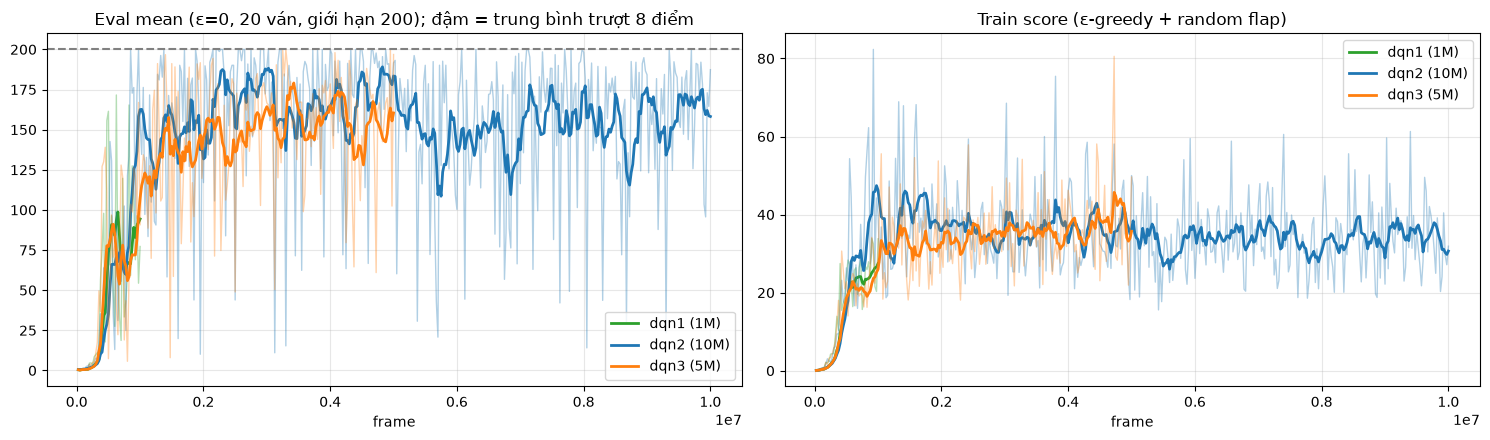

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, df in hist.items():
    axes[0].plot(df.frame, df.eval_mean, color=COLORS[name], alpha=0.35, lw=1)
    axes[0].plot(df.frame, df.eval_mean.rolling(8, min_periods=1).mean(), color=COLORS[name], lw=2, label=name)
    axes[1].plot(df.frame, df.train_score, color=COLORS[name], alpha=0.35, lw=1)
    axes[1].plot(df.frame, df.train_score.rolling(8, min_periods=1).mean(), color=COLORS[name], lw=2, label=name)
axes[0].axhline(200, ls="--", c="gray")
axes[0].set_title("Eval mean (ε=0, 20 ván, giới hạn 200); đậm = trung bình trượt 8 điểm")
axes[1].set_title("Train score (ε-greedy + random flap)")
for ax in axes:
    ax.set_xlabel("frame"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); save_fig(fig, "01_learning_curves"); plt.show()

**Nhận xét 1: đường học**

- Cùng seed **không** cho ra cùng đường học. dqn1 và dqn3 trùng tuyệt đối tới 175k rồi tách ra ở 200k (dqn1 được chạy tiếp từ 175k); dqn2 khác ngay từ bản ghi đầu (482 so với 483 ván tại 25k). Sau đó ba đường khác xa nhau: eval mean tại 400k là 75,1 / 13,85 / 127,05 và tại 500k là 161,45 / 58,3 / 7,35 (dqn1 / dqn2 / dqn3).
- Điểm chung là điểm đánh giá bắt đầu bứt lên trong khoảng 350–500k frame; đây là đặc điểm của cấu hình.
- dqn1 dừng ở 1M frame khi đường học còn dao động mạnh (nửa sau từ 18,7 đến 171,6) và chưa lần nào đạt 190.
- dqn2 chạm trần 200 lần đầu ở 850k. dqn3 đạt ≥ 190 lần đầu ở 1,275M (191,15) và chạm 200 lần đầu ở 3,25M. Sau đó cả hai dao động quanh 150–190 chứ không đi lên đều.
- Train score thấp hơn eval nhiều: cuối run chỉ khoảng 33–39 ống mỗi ván (trung bình 20 bản ghi cuối: dqn2 32,7; dqn3 38,8), trong khi eval với ε=0 đạt 150–200. Lúc train vẫn còn ε=0,01 và `random_flap_prob=0.1`, và vài hành động ngẫu nhiên đã đủ kết thúc ván.

## 2. Bảng tóm tắt

In [3]:
def first_reach(df, target):
    hit = df[df.eval_mean >= target]
    return int(hit.frame.iloc[0]) if len(hit) else None

def mean_last10_upto(df, frame):
    upto = df[df.frame <= frame]
    return round(upto.eval_mean.tail(10).mean(), 1) if df.frame.iloc[-1] >= frame else None

summary = pd.DataFrame({
    name: {
        "frame tổng": int(df.frame.iloc[-1]),
        "số phiên Colab": len(session_peaks(df)),
        "thời gian, tổng các phiên (phút)": round(sum(session_peaks(df)), 1),
        "eval mean tốt nhất": df.eval_mean.max(),
        # best.weights.h5 được lưu khi mean > best cũ, tức lần đầu đạt max
        "frame của best.weights.h5": int(df.frame[df.eval_mean.idxmax()]),
        "frame đầu tiên mean ≥ 100": first_reach(df, 100),
        "frame đầu tiên mean ≥ 190": first_reach(df, 190),
        "frame đầu tiên mean = 200": first_reach(df, 200),
        "số lần đánh giá mean ≥ 190": int((df.eval_mean >= 190).sum()),
        "TB 10 lần đánh giá tới 1M": mean_last10_upto(df, 1_000_000),
        "TB 10 lần đánh giá tới 5M": mean_last10_upto(df, 5_000_000),
        "TB 10 lần đánh giá cuối": round(df.eval_mean.tail(10).mean(), 1),
        "max Q trung bình (cuối)": round(df.mean_max_q.iloc[-1], 2),
    } for name, df in hist.items()
}).T
summary

,frame tổng,số phiên Colab,"thời gian, tổng các phiên (phút)",eval mean tốt nhất,frame của best.weights.h5,frame đầu tiên mean ≥ 100,frame đầu tiên mean ≥ 190,frame đầu tiên mean = 200,số lần đánh giá mean ≥ 190,TB 10 lần đánh giá tới 1M,TB 10 lần đánh giá tới 5M,TB 10 lần đánh giá cuối,max Q trung bình (cuối)
dqn1 (1M),1000000.0,2.0,76.5,171.6,625000.0,475000.0,NaN,NaN,0.0,85.7,NaN,85.7,10.26
dqn2 (10M),10000000.0,3.0,1080.6,200.0,850000.0,525000.0,850000.0,850000.0,98.0,144.6,180.8,164.7,12.20
dqn3 (5M),5000000.0,2.0,545.2,200.0,3250000.0,400000.0,1275000.0,3250000.0,16.0,90.9,160.7,160.7,12.39


**Nhận xét 2: bảng tóm tắt**

| | dqn1 (1M) | dqn2 (10M) | dqn3 (5M) |
|---|---|---|---|
| Thời gian (tổng các phiên) | 76,5 phút (2 phiên) | 1.080,6 phút ≈ 18,0 giờ (3 phiên) | 545,2 phút ≈ 9,1 giờ (2 phiên) |
| Khung hình của `best.weights.h5` | 625k | 850k | 3,25M |
| Frame đầu tiên mean ≥ 100 | 475k | 525k | 400k |
| TB 10 lần đánh giá tới mốc 1M | 85,7 | 144,6 | 90,9 |
| TB 10 lần đánh giá tới mốc 5M | – | 180,8 | 160,7 |
| TB 10 lần đánh giá cuối run | 85,7 | 164,7 | 160,7 |

- **Không so được "thời lượng huấn luyện" bằng cách đặt ba run cạnh nhau.** Ở cùng mốc 1M, ba run đã chênh nhau 85,7 / 144,6 / 90,9, tức chênh lệch ngẫu nhiên giữa các run đã cỡ hiệu ứng muốn đo.
- So trong **cùng một run** thì đáng tin hơn. Eval mean trung bình theo từng triệu frame của dqn2: (1M–2M] 143,5; (2M–3M] 176,8; (3M–4M] 159,9; (4M–5M] 171,1; (5M–6M] 143,5; (9M–10M] 158,6. Điểm ngừng tăng từ khoảng 2–3M, sau đó chỉ dao động.
- 10M mất khoảng gấp đôi 5M (18,0 so với 9,1 giờ). Phần lớn thời gian là đánh giá: một chu kỳ 25k frame mất khoảng 1 phút khi agent còn kém, nhưng 3,1–4,3 phút khi cả 20 ván đánh giá đều đạt 200 ống.

## 3. Độ ổn định: dao động của điểm đánh giá

Sau 1M frame, eval mean:
       dqn1 (1M)  dqn2 (10M)  dqn3 (5M)
count        1.0       361.0      160.0
mean        77.2       157.0      148.4
std          NaN        44.1       36.8
min         77.2        10.1        8.0
25%         77.2       140.8      129.6
50%         77.2       172.0      157.0
75%         77.2       190.1      174.4
max         77.2       200.0      200.0

Eval mean trung bình theo từng triệu frame của dqn2:
frame
(0M, 1M]      63.0
(1M, 2M]     143.5
(2M, 3M]     176.8
(3M, 4M]     159.9
(4M, 5M]     171.1
(5M, 6M]     143.5
(6M, 7M]     144.7
(7M, 8M]     163.1
(8M, 9M]     151.6
(9M, 10M]    158.6
Name: eval_mean, dtype: float64


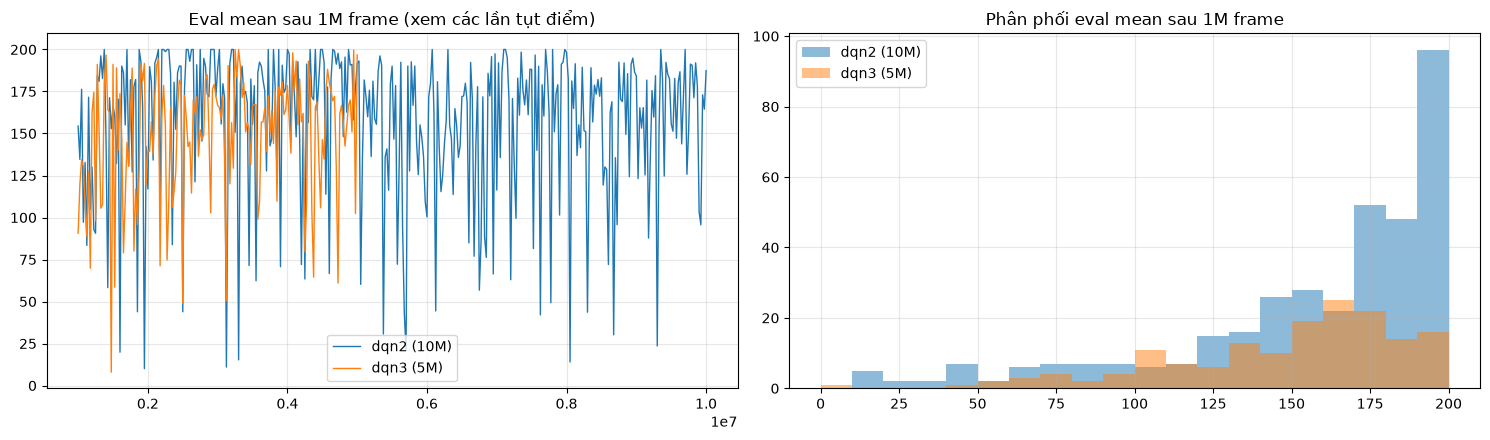

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, df in hist.items():
    late = df[df.frame >= 1_000_000]
    if len(late) < 2:  # dqn1 chỉ có một điểm sau 1M
        continue
    axes[0].plot(late.frame, late.eval_mean, color=COLORS[name], lw=1, label=name)
    axes[1].hist(late.eval_mean, bins=np.arange(0, 205, 10), alpha=.5, color=COLORS[name], label=name)
axes[0].set_title("Eval mean sau 1M frame (xem các lần tụt điểm)")
axes[1].set_title("Phân phối eval mean sau 1M frame")
for ax in axes:
    ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); save_fig(fig, "02_stability"); plt.show()

print("Sau 1M frame, eval mean:")
print(pd.DataFrame({n: d[d.frame >= 1_000_000].eval_mean.describe() for n, d in hist.items()}).round(1))

print("\nEval mean trung bình theo từng triệu frame của dqn2:")
dqn2 = hist["dqn2 (10M)"]
print(dqn2.groupby((dqn2.frame - 1) // 1_000_000).eval_mean.mean().round(1).rename(lambda m: f"({m}M, {m + 1}M]"))

**Nhận xét 3: độ ổn định**

- Sau khi đã đạt 190–200, dqn2 và dqn3 vẫn nhiều lần tụt mạnh, ví dụ dqn2 còn 81,6 tại 7,5M và dqn3 còn 79,6 tại 4,25M; thấp nhất sau 1M là 10,1 (dqn2) và 8,0 (dqn3).
- Các lần tụt thường hồi phục ngay ở lần đánh giá kế tiếp và không đi xuống dần. Mỗi điểm chỉ có 20 ván nên bản thân nó nhiễu: một ván chết sớm kéo trung bình xuống nhiều.
- Có hai cách giải thích, và dữ liệu hiện có chưa tách được: (a) nhiễu đo của 20 ván, (b) chính sách thật sự dao động, ví dụ do replay buffer 100k làm quên tình huống hiếm. Cách (b) là **giả thuyết**, chưa kiểm chứng.
- Điều kiện thêm Prioritised Replay trong tài liệu là điểm đánh giá *tăng rồi tụt và không hồi phục*. Ở đây điểm có tụt nhưng hồi phục ngay, nên điều kiện **chưa thỏa**.

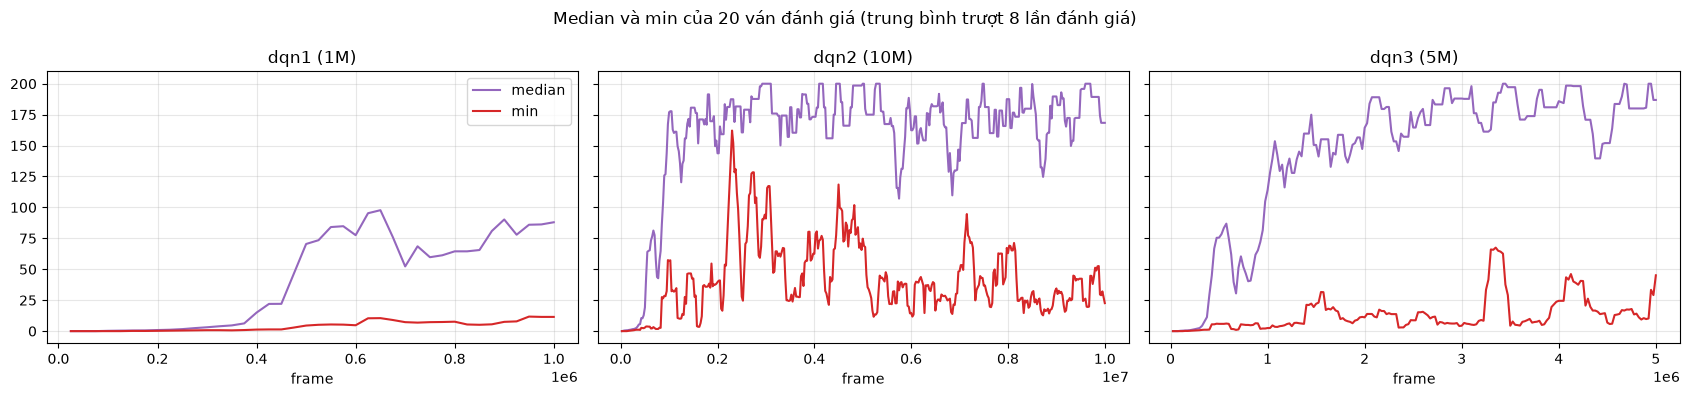

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, (name, df) in zip(axes, hist.items()):
    ax.plot(df.frame, df.eval_median.rolling(8, min_periods=1).mean(), label="median", color="tab:purple")
    ax.plot(df.frame, df.eval_min.rolling(8, min_periods=1).mean(), label="min", color="tab:red")
    ax.set_title(name); ax.set_xlabel("frame"); ax.grid(alpha=.3)
axes[0].legend()
fig.suptitle("Median và min của 20 ván đánh giá (trung bình trượt 8 lần đánh giá)")
plt.tight_layout(); save_fig(fig, "03_median_min_max"); plt.show()

**Nhận xét 3b: median và min**

(Hình dùng trung bình trượt 8 lần đánh giá để đọc được; giá trị max hầu như luôn là 200 nên không vẽ.)

- Ở dqn2 và dqn3, median (trung bình trượt) phần lớn thời gian ở khoảng 150–200 trong khi min hầu hết dưới 50: **đa số ván đạt giới hạn, mean bị kéo xuống bởi một vài ván chết sớm**. Thất bại thưa nhưng nặng.
- Chưa biết các ván chết sớm có chung một kiểu khe ống hay không. Điểm từng ván không được lưu, nên chưa kết luận được.

## 4. Q-value, loss và số episode

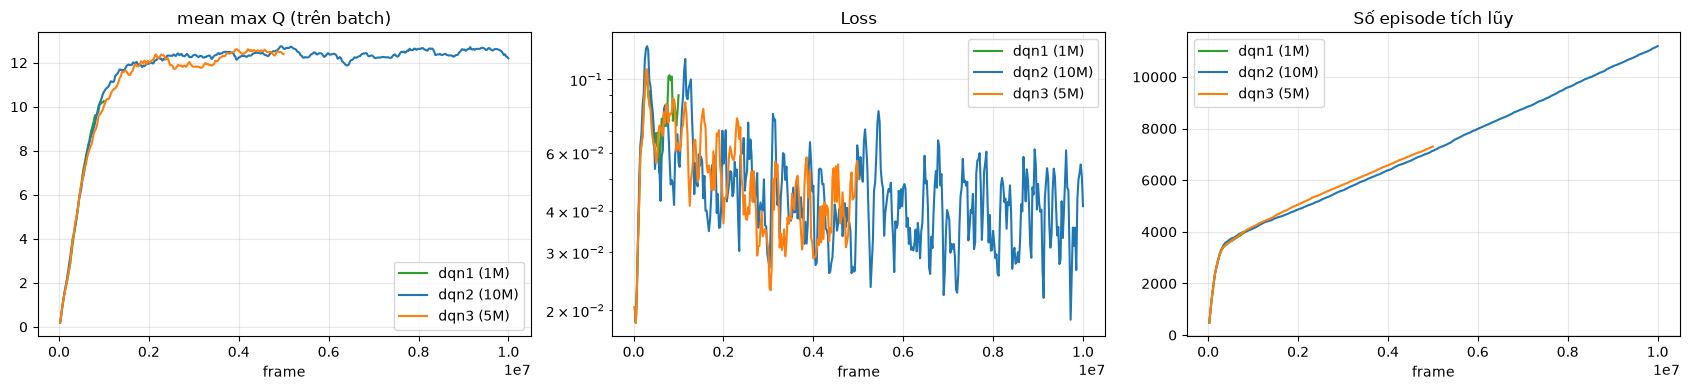

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, df in hist.items():
    axes[0].plot(df.frame, df.mean_max_q, color=COLORS[name], label=name)
    axes[1].plot(df.frame, df.loss, color=COLORS[name], label=name)
    axes[2].plot(df.frame, df.episodes, color=COLORS[name], label=name)
axes[0].set_title("mean max Q (trên batch)")
axes[1].set_title("Loss"); axes[1].set_yscale("log")
axes[2].set_title("Số episode tích lũy")
for ax in axes:
    ax.set_xlabel("frame"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); save_fig(fig, "04_q_loss_episodes"); plt.show()

**Nhận xét 4: Q và loss**

- mean max Q tăng nhanh tới khoảng 10,0–10,7 ở mốc 1M và vào vùng 12 từ khoảng 2M, rồi ổn định quanh 12,2–12,5 ở dqn2 và dqn3, không bùng nổ và nằm dưới ngưỡng 12,9 mà tài liệu coi là dấu hiệu đánh giá quá cao.
- Không có run đối chứng bỏ Double DQN, nên chưa thể quy việc Q ổn định cho Double DQN.
- Loss giảm từ khoảng 0,08–0,1 xuống khoảng 0,04–0,05 rồi đứng yên, và không báo trước các lần tụt điểm, nên không dùng được làm tín hiệu dừng.
- Số episode tăng chậm dần vì ván dài hơn: dqn2 chỉ khoảng 11,2k episode trong 10M frame.

## 5. Đánh giá cuối (`best.weights.h5`, 100 ván, giới hạn 1000)

In [7]:
# Số lấy từ output cuối của 3 notebook Colab đã chạy (Results/dqn_run*/FlappyBird_Colab_*.ipynb).
# Điểm từng ván không được lưu, nên chỉ có các thống kê này.
final = pd.DataFrame({
    "dqn1 (1M)":  {"mean": 341.60, "median": 294,  "min": 3,  "max": 1000, "ván chạm 1000": "2/100",  "max Q TB": 8.16},
    "dqn2 (10M)": {"mean": 908.77, "median": 1000, "min": 1,  "max": 1000, "ván chạm 1000": "90/100", "max Q TB": 9.95},
    "dqn3 (5M)":  {"mean": 910.72, "median": 1000, "min": 53, "max": 1000, "ván chạm 1000": "83/100", "max Q TB": 12.00},
}).T
final.insert(0, "checkpoint (frame)", summary["frame của best.weights.h5"])
final

,checkpoint (frame),mean,median,min,max,ván chạm 1000,max Q TB
dqn1 (1M),625000.0,341.6,294,3,1000,2/100,8.16
dqn2 (10M),850000.0,908.77,1000,1,1000,90/100,9.95
dqn3 (5M),3250000.0,910.72,1000,53,1000,83/100,12.0


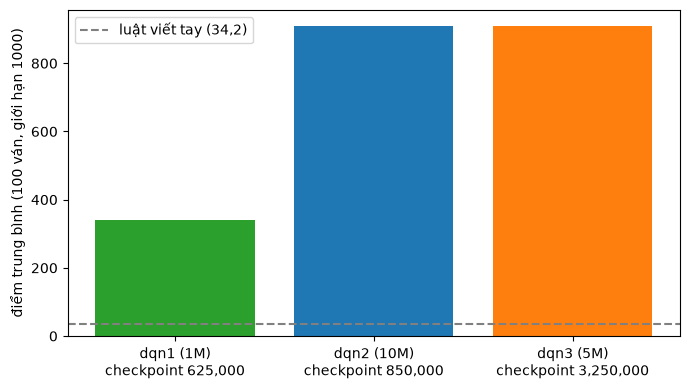

In [8]:
labels = [f"{name}\ncheckpoint {int(final.loc[name, 'checkpoint (frame)']):,}" for name in final.index]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, final["mean"].astype(float), color=[COLORS[n] for n in final.index])
ax.axhline(34.2, ls="--", c="gray", label="luật viết tay (34,2)")
ax.legend(loc="upper left")
ax.set_ylabel("điểm trung bình (100 ván, giới hạn 1000)")
plt.tight_layout(); save_fig(fig, "05_final_eval"); plt.show()

**Nhận xét 5: đánh giá cuối**

- Bảng này **không phải** so sánh 1M / 10M / 5M. Ba checkpoint được chấm là ở 625k, 850k và 3,25M frame (cột `checkpoint`). Phần còn lại của dqn2 (9,15M frame) và dqn3 (1,75M frame) chưa được đánh giá 100 ván, dù `last.weights.h5` và các snapshot vẫn còn.
- Cả ba **vượt xa mốc so sánh** (ngẫu nhiên 0, luật viết tay 34,2 ống mỗi ván).
- Checkpoint 850k của dqn2 (908,8) và checkpoint 3,25M của dqn3 (910,7) cho kết quả ngang nhau. Vì vậy dữ liệu **không** cho thấy cần 5M frame: một checkpoint chưa tới 1M (khoảng 1 giờ trên Colab) đã đạt mức này. Ngược lại, checkpoint 625k của dqn1 chỉ đạt 341,6, tức kết quả tại cùng một mốc phụ thuộc nhiều vào từng lần chạy.
- max Q trung bình trên các trạng thái đã đi qua là 8,16 / 9,95 / 12,00. Hai giá trị đầu thấp hơn vùng 11,9–12,9 mà tài liệu dự đoán cho agent chơi tốt, đúng với việc chúng là checkpoint sớm. Không trạng thái nào vượt 12,9.
- Seed đánh giá 12345 cũng là seed dùng để chọn `best`, nên đánh giá cuối không hoàn toàn độc lập với bước chọn mô hình.

## 6. Kết luận

1. **Cấu hình hiện tại học được**: checkpoint tốt nhất của dqn2 và dqn3 đạt khoảng 910 trên 1000 ống (83–90% ván chạm giới hạn), vượt xa luật viết tay (34,2).
2. **Chưa kết luận được về thời lượng huấn luyện cần thiết.** Ba run là ba lần lặp; chênh lệch giữa chúng ở cùng mốc đã lớn. Trong dqn2, điểm đánh giá ngừng tăng từ khoảng 2–3M frame.
3. **Kết quả giữa các lần chạy dao động mạnh**: tại 1M frame, trung bình 10 lần đánh giá gần nhất là 85,7 / 144,6 / 90,9.
4. **Điểm đánh giá dao động sau khi đã giỏi**, nhưng thường hồi phục ngay; chưa tách được nhiễu đo với dao động thật của chính sách.
5. **Bước tiếp theo, theo thứ tự**: (a) đánh giá 100 ván cho `last.weights.h5` và một số snapshot để có so sánh đúng; (b) sửa tiêu chí chọn `best` (điểm bị chặn ở 200 nên lần đầu chạm trần được giữ mãi); (c) thử giảm ε về 0,001 sau khi agent đã giỏi; (d) chỉ thêm Prioritised Replay nếu điểm tụt mà không hồi phục.
6. **Giới hạn**: một cấu hình, ba lần lặp; mỗi điểm đánh giá 20 ván; không có run đối chứng (bỏ Double hoặc Dueling); điểm từng ván của đánh giá cuối không được lưu.